# Can countries grow richer while cutting emissions?

**Research question.** Between 2005 and 2019, which countries grew their economies while *reducing* CO₂ emissions ("absolute decoupling"), and does that still hold once emissions embedded in imported goods are counted?

**Why the second part matters.** Standard (territorial) figures count emissions where they are produced. A country can look greener by importing goods made elsewhere. *Consumption-based* emissions reassign those emissions to the country that consumes the goods.

**Data.** [Our World in Data CO₂ and greenhouse gas emissions dataset](https://github.com/owid/co2-data) (emissions from the Global Carbon Project; GDP from the Maddison Project Database, adjusted for inflation and price differences). Consumption-based estimates exist for ~120 countries.

**Window.** 2005 (the year the Kyoto Protocol came into force) to 2019, ending before the 2020 COVID-19 dip distorts both GDP and emissions.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
BG, FG, MUTED, A1, A2, A3, A4 = '#0F0E17', '#F4F1EA', '#9A93A8', '#E8577C', '#E8B86D', '#6D5EF5', '#38BDF8'
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'axes.edgecolor':'#3a3747','axes.labelcolor':MUTED,
  'xtick.color':MUTED,'ytick.color':MUTED,'text.color':FG,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
  'axes.grid':True,'axes.axisbelow':True,'grid.color':'#24222f','savefig.facecolor':BG,'savefig.dpi':160,'legend.frameon':False})

In [2]:
URL = 'https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv'
try:
    raw = pd.read_csv('owid-co2-data.csv')
except FileNotFoundError:
    raw = pd.read_csv(URL)
countries = raw[raw['iso_code'].str.len().eq(3).fillna(False)]   # drops regions and income groups
cols = ['country','iso_code','year','population','gdp','co2','consumption_co2']
d = countries[countries['year'].isin([2005, 2019])][cols]
w = d.pivot(index=['country','iso_code'], columns='year', values=['population','gdp','co2','consumption_co2'])
w.columns = [f'{a}_{b}' for a,b in w.columns]
w = w.reset_index()
keep = (w['population_2019'] >= 1e6) & w[['gdp_2005','gdp_2019','co2_2005','co2_2019','consumption_co2_2005','consumption_co2_2019']].notna().all(axis=1)
w = w[keep].copy()
print('Countries with population 1m+ and complete GDP, territorial and consumption data:', len(w))
print(f"They account for {w['co2_2019'].sum()/countries[countries.year==2019]['co2'].sum():.0%} of 2019 territorial CO2 from all countries in the dataset")

Countries with population 1m+ and complete GDP, territorial and consumption data: 117
They account for 97% of 2019 territorial CO2 from all countries in the dataset


## 1. Classify each country

Absolute decoupling: GDP up **and** emissions down. Relative: both up, emissions slower. None: emissions grew at least as fast as GDP.

In [3]:
for base in ['co2','consumption_co2']:
    w[f'{base}_chg'] = w[f'{base}_2019']/w[f'{base}_2005'] - 1
w['gdp_chg'] = w['gdp_2019']/w['gdp_2005'] - 1
def cls(g, e):
    if g <= 0: return 'GDP fell'
    if e < 0: return 'Absolute decoupling'
    if e < g: return 'Relative decoupling'
    return 'No decoupling'
w['territorial'] = [cls(g,e) for g,e in zip(w['gdp_chg'], w['co2_chg'])]
w['consumption'] = [cls(g,e) for g,e in zip(w['gdp_chg'], w['consumption_co2_chg'])]
order = ['Absolute decoupling','Relative decoupling','No decoupling','GDP fell']
tab = pd.DataFrame({'Territorial': w['territorial'].value_counts(), 'Consumption-based': w['consumption'].value_counts()}).reindex(order).fillna(0).astype(int)
print(tab)
print('\nCross-tab (rows: territorial, columns: consumption-based):')
print(pd.crosstab(w['territorial'], w['consumption']).reindex(index=order, columns=order, fill_value=0))

                     Territorial  Consumption-based
Absolute decoupling           34                 28
Relative decoupling           59                 54
No decoupling                 22                 33
GDP fell                       2                  2

Cross-tab (rows: territorial, columns: consumption-based):
consumption          Absolute decoupling  Relative decoupling  No decoupling  \
territorial                                                                    
Absolute decoupling                   26                    7              1   
Relative decoupling                    2                   41             16   
No decoupling                          0                    6             16   
GDP fell                               0                    0              0   

consumption          GDP fell  
territorial                    
Absolute decoupling         0  
Relative decoupling         0  
No decoupling               0  
GDP fell                    2  


In [4]:
both = w[(w['territorial']=='Absolute decoupling') & (w['consumption']=='Absolute decoupling')]
lost = w[(w['territorial']=='Absolute decoupling') & (w['consumption']!='Absolute decoupling')]
gained = w[(w['territorial']!='Absolute decoupling') & (w['consumption']=='Absolute decoupling')]
print(f'Absolute decoupling on BOTH measures: {len(both)} countries')
print(both.sort_values('gdp_chg', ascending=False)[['country','gdp_chg','co2_chg','consumption_co2_chg']].round(3).to_string(index=False))
print(f'\nDecoupled on territorial only (disappears once imports are counted): {len(lost)}')
print(lost[['country','gdp_chg','co2_chg','consumption_co2_chg']].round(3).to_string(index=False))
print(f'\nDecoupled on consumption only: {len(gained)}')
print(gained[['country','gdp_chg','co2_chg','consumption_co2_chg']].round(3).to_string(index=False))

Absolute decoupling on BOTH measures: 26 countries
       country  gdp_chg  co2_chg  consumption_co2_chg
       Romania    0.871   -0.243               -0.170
      Slovakia    0.573   -0.210               -0.034
       Czechia    0.518   -0.197               -0.005
   New Zealand    0.474   -0.018               -0.044
       Hungary    0.456   -0.183               -0.269
        Norway    0.446   -0.010               -0.047
      Bulgaria    0.444   -0.166               -0.182
       Ireland    0.437   -0.227               -0.335
       Germany    0.319   -0.183               -0.190
        Sweden    0.317   -0.242               -0.227
       Croatia    0.266   -0.235               -0.197
      Slovenia    0.264   -0.171               -0.032
 United States    0.264   -0.145               -0.162
   Netherlands    0.258   -0.143               -0.201
       Austria    0.247   -0.141               -0.176
       Belgium    0.242   -0.206               -0.042
       Estonia    0.234   -0.28

## 2. Is the gap between the measures systematic?

In [5]:
w['gap_2019'] = (w['consumption_co2_2019'] - w['co2_2019']) / w['co2_2019']   # >0: net importer of emissions
w['gdp_pc_2019'] = w['gdp_2019']/w['population_2019']
rho, p = stats.spearmanr(w['gdp_pc_2019'], w['gap_2019'])
print(f'Spearman correlation, GDP per person vs net imported emissions share: rho={rho:.2f}, p={p:.2g}')
w['income_group'] = pd.qcut(w['gdp_pc_2019'], 3, labels=['Lower third','Middle third','Richest third'])
print(w.groupby('income_group', observed=True).agg(countries=('country','size'), median_imported_share=('gap_2019','median'),
      share_abs_decoupled_territorial=('territorial', lambda s:(s=='Absolute decoupling').mean()),
      share_abs_decoupled_consumption=('consumption', lambda s:(s=='Absolute decoupling').mean())).round(3))

Spearman correlation, GDP per person vs net imported emissions share: rho=-0.12, p=0.19
               countries  median_imported_share  \
income_group                                      
Lower third           39                  0.329   
Middle third          39                  0.136   
Richest third         39                  0.146   

               share_abs_decoupled_territorial  \
income_group                                     
Lower third                              0.051   
Middle third                             0.154   
Richest third                            0.667   

               share_abs_decoupled_consumption  
income_group                                    
Lower third                              0.000  
Middle third                             0.103  
Richest third                            0.615  


## 3. Charts

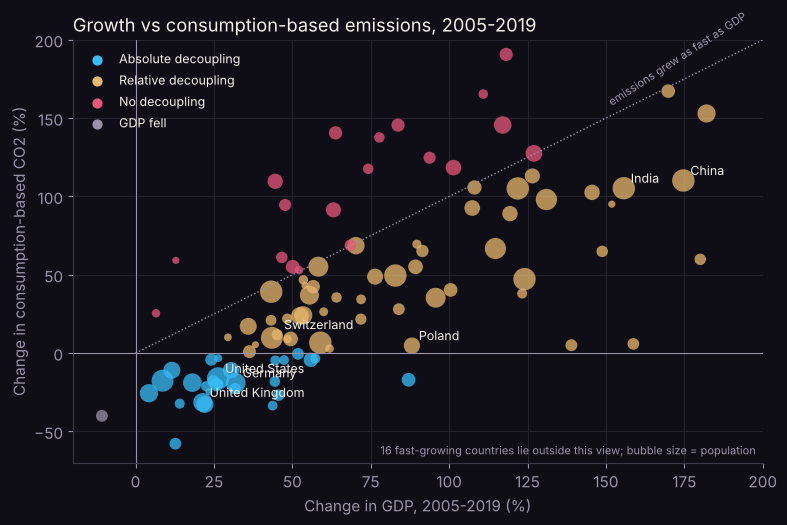

In [6]:
fig, ax = plt.subplots(figsize=(8,5.4))
XL, YL = (-20, 200), (-70, 200)
inview = w['gdp_chg'].mul(100).between(*XL) & w['consumption_co2_chg'].mul(100).between(*YL)
colors = {'Absolute decoupling':A4,'Relative decoupling':A2,'No decoupling':A1,'GDP fell':MUTED}
for k,c in colors.items():
    s = w[(w['consumption']==k) & inview]
    ax.scatter(s['gdp_chg']*100, s['consumption_co2_chg']*100, s=np.clip(np.sqrt(s['population_2019'])/45, 12, 260), color=c, alpha=0.75, edgecolor='none')
    ax.scatter([], [], s=40, color=c, label=k)
ax.plot([0,XL[1]],[0,XL[1]], color=MUTED, ls=':', lw=1); ax.text(150, 158, 'emissions grew as fast as GDP', color=MUTED, fontsize=8, rotation=33)
ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
for name in ['United Kingdom','United States','China','India','Germany','Poland','Switzerland']:
    r = w[w['country']==name]
    if len(r): ax.annotate(name, (r['gdp_chg'].iloc[0]*100, r['consumption_co2_chg'].iloc[0]*100), xytext=(5,4), textcoords='offset points', fontsize=9, color=FG)
ax.set_xlim(*XL); ax.set_ylim(*YL)
ax.set_xlabel('Change in GDP, 2005-2019 (%)'); ax.set_ylabel('Change in consumption-based CO2 (%)')
ax.set_title('Growth vs consumption-based emissions, 2005-2019', loc='left', color=FG)
ax.text(0.99, 0.02, f'{(~inview).sum()} fast-growing countries lie outside this view; bubble size = population', transform=ax.transAxes, ha='right', fontsize=8, color=MUTED)
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout(); fig.savefig('figures/01_growth_vs_emissions.png'); plt.show()

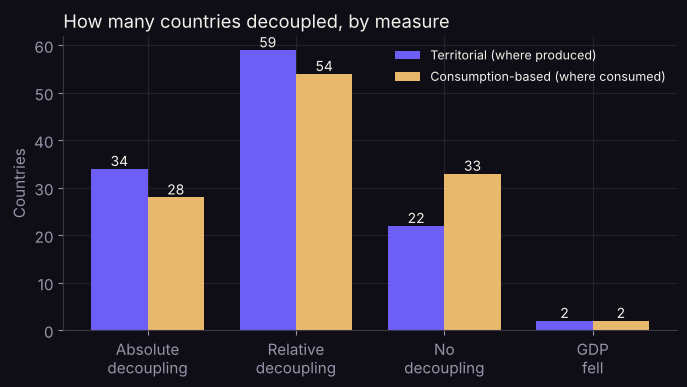

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
x = np.arange(len(order)); wdt = 0.38
ax.bar(x-wdt/2, tab['Territorial'], wdt, color=A3, label='Territorial (where produced)')
ax.bar(x+wdt/2, tab['Consumption-based'], wdt, color=A2, label='Consumption-based (where consumed)')
for i in range(len(order)):
    ax.text(i-wdt/2, tab['Territorial'].iloc[i]+0.6, tab['Territorial'].iloc[i], ha='center', fontsize=10)
    ax.text(i+wdt/2, tab['Consumption-based'].iloc[i]+0.6, tab['Consumption-based'].iloc[i], ha='center', fontsize=10)
ax.set_xticks(x, [o.replace(' ','\n',1) for o in order]); ax.set_ylabel('Countries'); ax.legend(fontsize=9)
ax.set_title('How many countries decoupled, by measure', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/02_decoupling_by_measure.png'); plt.show()

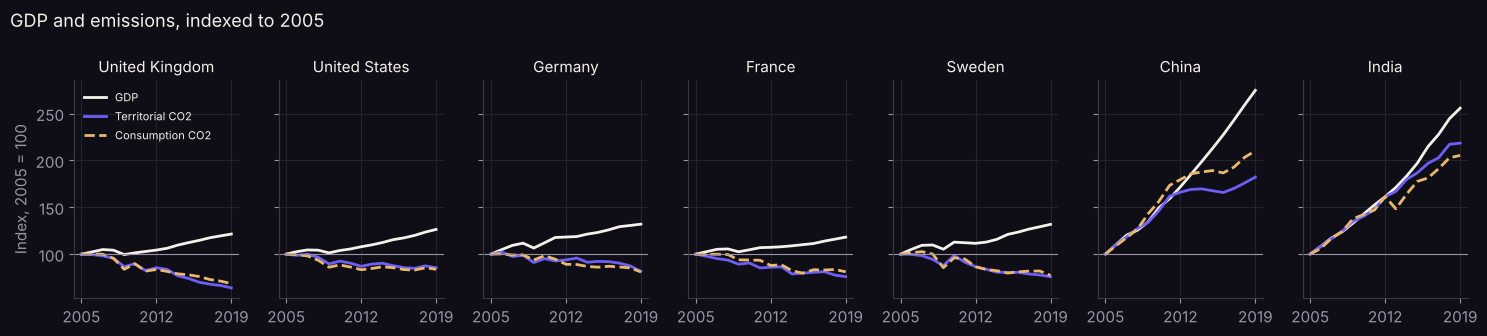

In [8]:
sel = ['United Kingdom','United States','Germany','France','Sweden','China','India']
ts = countries[countries['country'].isin(sel) & countries['year'].between(2005,2019)].set_index(['country','year'])[['gdp','co2','consumption_co2']]
fig, axes = plt.subplots(1, len(sel), figsize=(15,3.4), sharey=True)
for ax, name in zip(axes, sel):
    t = ts.loc[name]; b = t.loc[2005]
    ax.plot(t.index, t['gdp']/b['gdp']*100, color=FG, lw=2, label='GDP')
    ax.plot(t.index, t['co2']/b['co2']*100, color=A3, lw=2, label='Territorial CO2')
    ax.plot(t.index, t['consumption_co2']/b['consumption_co2']*100, color=A2, lw=2, ls='--', label='Consumption CO2')
    ax.axhline(100, color=MUTED, lw=0.8); ax.set_title(name, fontsize=11, color=FG); ax.set_xticks([2005,2012,2019])
axes[0].set_ylabel('Index, 2005 = 100'); axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle('GDP and emissions, indexed to 2005', x=0.01, ha='left', color=FG, fontsize=13)
fig.tight_layout(); fig.savefig('figures/03_selected_countries.png'); plt.show()

In [9]:
w.sort_values('country')[['country','gdp_chg','co2_chg','consumption_co2_chg','territorial','consumption','gap_2019']].round(3).to_csv('figures/country_results.csv', index=False)

## Limitations

- **Two end points.** Comparing 2005 with 2019 ignores the path between; one unusual year at either end can move a country between categories.
- **Consumption-based estimates are modelled** from trade data and carry more uncertainty than territorial figures, especially for smaller economies.
- **CO₂ only** (fossil fuels and industry). Other greenhouse gases and land use are excluded.
- **Coverage.** Only ~120 countries have consumption estimates; most small and many low-income countries are missing.
- **Decoupling is not sufficiency.** Falling emissions can still be far too slow for climate targets.